## Importance analysis with SHAP

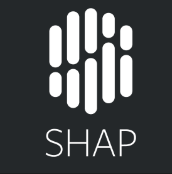


<i>

<br>

This notebook shows a basic analysis using feature importances (Shapley values.)

### <i> Imports

In [1]:
# pip install catboost
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from catboost import CatBoostRegressor
from sklearn import metrics

c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\xgboost\compat.py:105: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


### <i> Loading

In [2]:
# Load the dataframe
df = pd.read_csv("../diamonds.csv")
df = df.drop("Unnamed: 0", axis=1)
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


### <i> Numeric Encoding

`cut` `color` `clarity`

In [3]:
# Ordinal mapping cut
category_mapper = {
    'Fair':0,
    'Good':1,
    'Very Good':2,
    'Premium': 3,
    'Ideal': 4
}
df['cut'] = df['cut'].map(category_mapper)

# Ordinal mapping color
category_mapper = {
    "D": 0,
    "E": 1,
    "F": 2,
    "G": 3,
    "H": 4,
    "I": 5,
    "J": 6
}
df["color"] = df["color"].map(category_mapper)

category_mapper = {
    "IF": 0,
    "VVS1": 1,
    "VVS2": 2,
    "VS1": 3,
    "VS2": 4,
    "SI1": 5,
    "SI2": 6,
    "I1": 7
}
df["clarity"] = df["clarity"].map(category_mapper)

df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4,1,6,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3,1,5,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1,1,3,56.9,65.0,327,4.05,4.07,2.31
3,0.29,3,5,4,62.4,58.0,334,4.20,4.23,2.63
4,0.31,1,6,6,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,4,0,5,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,1,0,5,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,2,0,5,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,3,4,6,61.0,58.0,2757,6.15,6.12,3.74


--- 

## Model training and Shap importance analysis

In [4]:
# X, y -- Test, train split
X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = CatBoostRegressor(
    iterations=50,
    loss_function="RMSE",
    verbose=0,
    random_seed=42
)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)
print("Model trained and y_pred predicted")

# Metrics recording
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
r_sq = metrics.r2_score(y_test, y_pred)
print("Metrics generated")

# Printing metrics
print("--------------------------")
print("METRICS")
print("--------------------------")
print("MAE")
print(f"{round(mae,2)} \n")
print("MSE")
print(f"{round(mse,2)} \n")
print("RMSE")
print(f"{round(rmse,2)} \n")
print('R-squared:')
print(f"{round(r_sq,2)} \n")


Model trained and y_pred predicted
Metrics generated
--------------------------
METRICS
--------------------------
MAE
309.95 

MSE
312250.44 

RMSE
558.79 

R-squared:
0.98 



---

### <i> Retrieving shap values

In [5]:
# Generate SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
print("Shap values created")

Shap values created


In [6]:
### <i> Bar plot

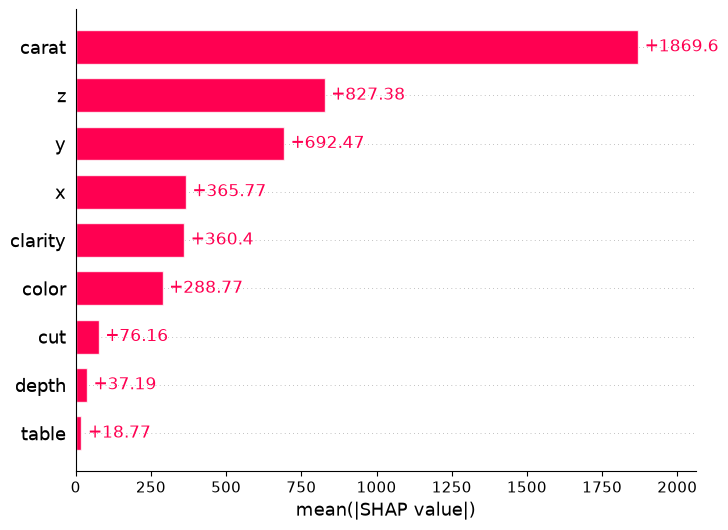

In [7]:
shap.plots.bar(shap_values)

### <i> Beeswarm plot

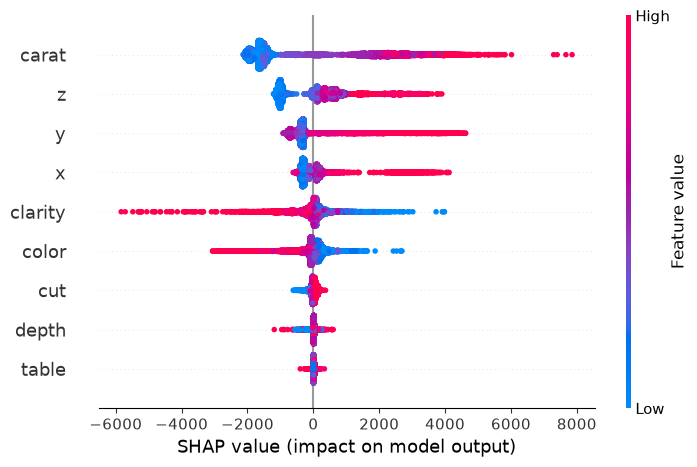

In [8]:
shap.plots.beeswarm(shap_values)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Observations</h3>

* `carat` appears to be the most important feature. We see some strange gaps in importance distributions, but roughly the values appear gradient enough.

* `depth`, `table`, and `cut` appear to have value little to no Shapley importance impact on the regression prediction at all! It could be overwhelmed by other features.



</div>

### <i> Dependency/Scatter plot


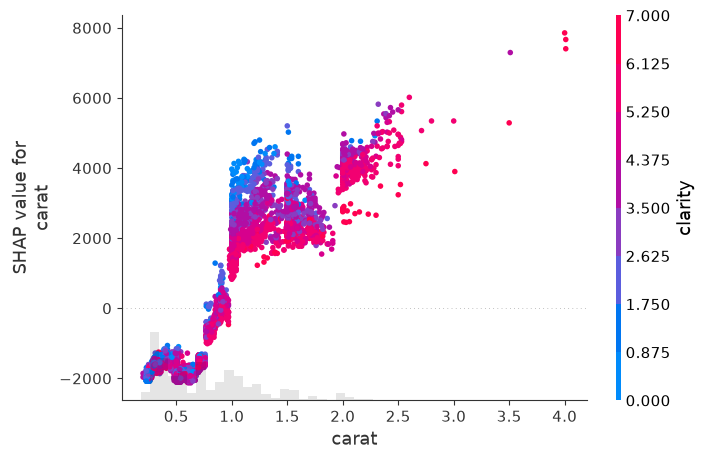

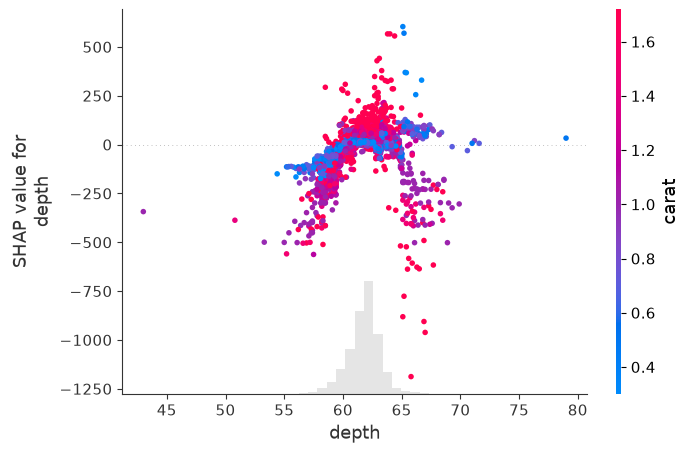

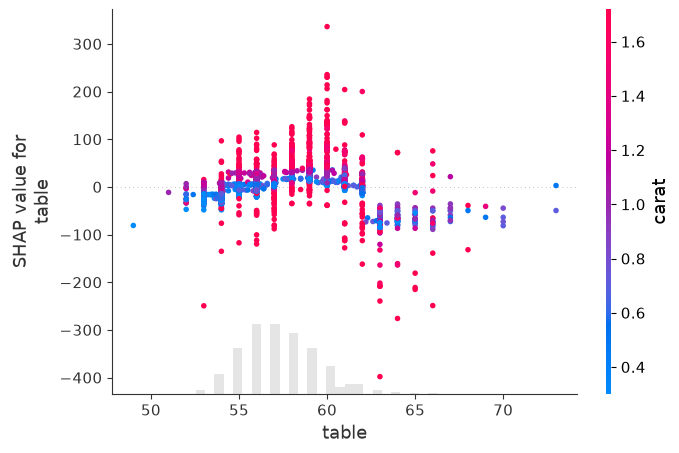

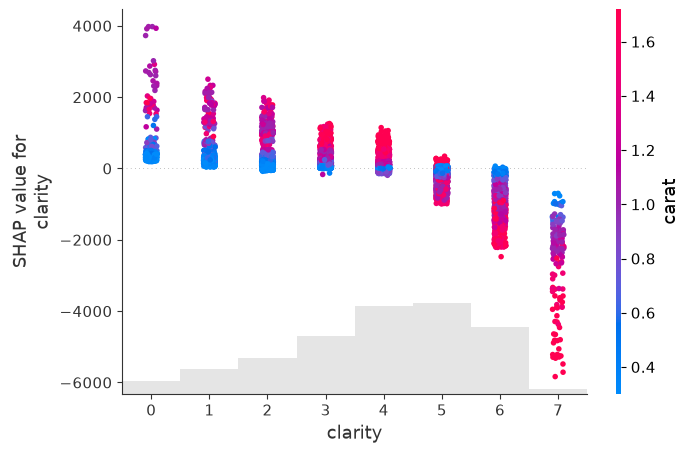

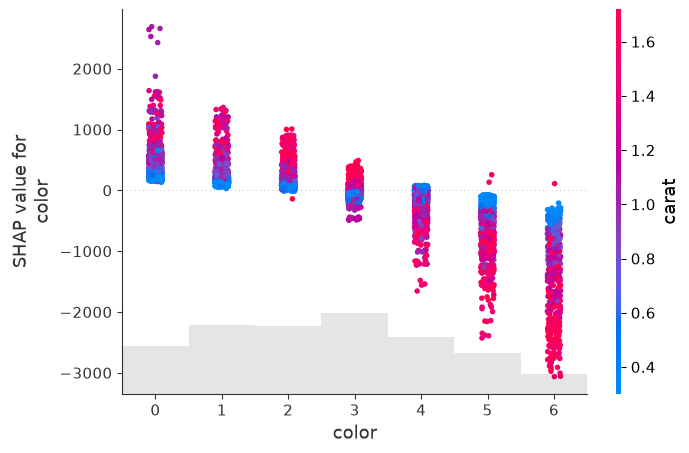

In [9]:
features = ["carat", "depth", "table", "clarity", "color"]

for feature in features:

    shap.plots.scatter(
        shap_values[:, feature],
        color=shap_values,
        show=True
    )

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">
<h3> Insights </h3>


* <i> `Carat` has a really strange, noisy dispertion pattern. 

* `color` `clarity` appears to have a non linear relationships, suggesting that there IS something there of value.

* `table` has a completely linear relationship. It could be that that numbers are really small. 


`carat` in particular is a little concerning. And it suggest that the primary focus point for optimization could be inside this feature.

</div>



### <h3> Shap vs Error Scatter plot

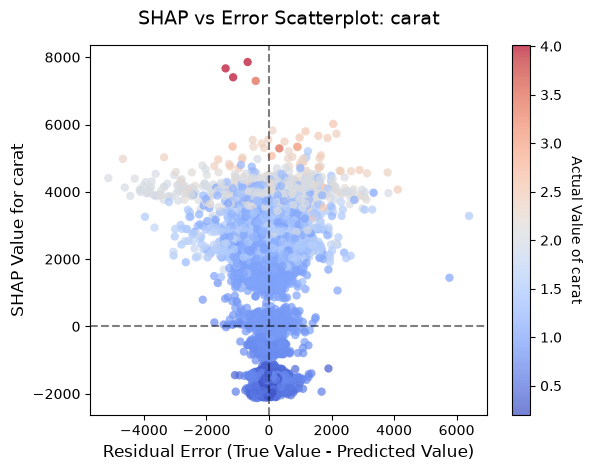

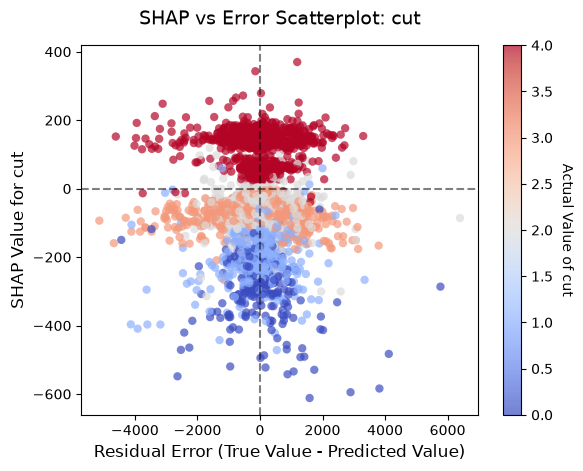

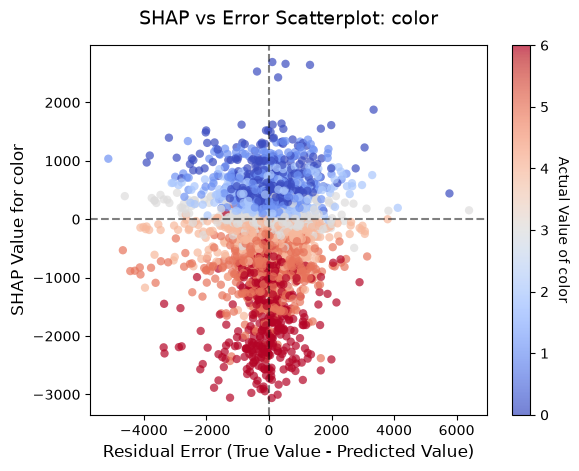

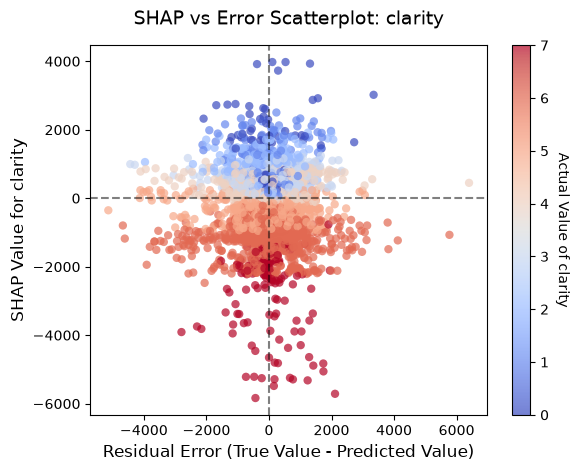

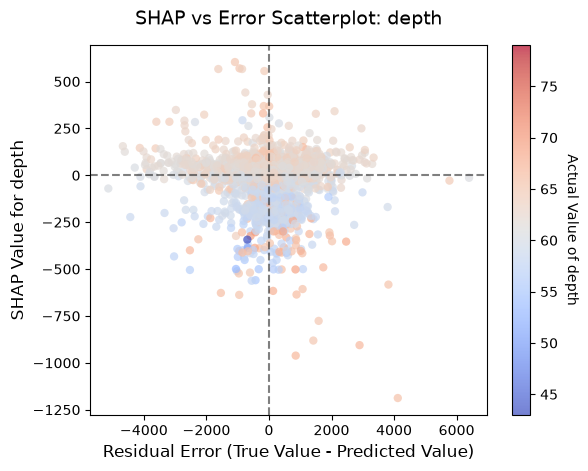

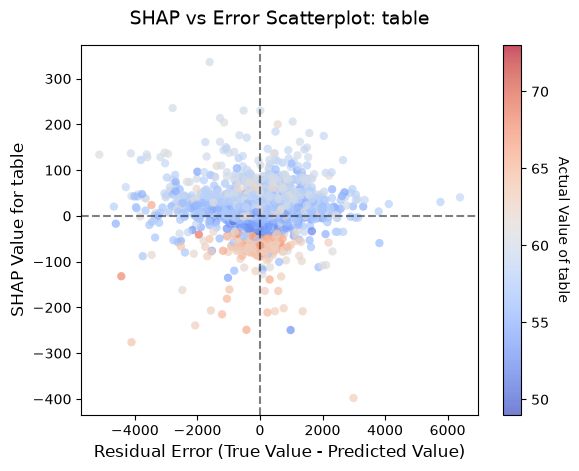

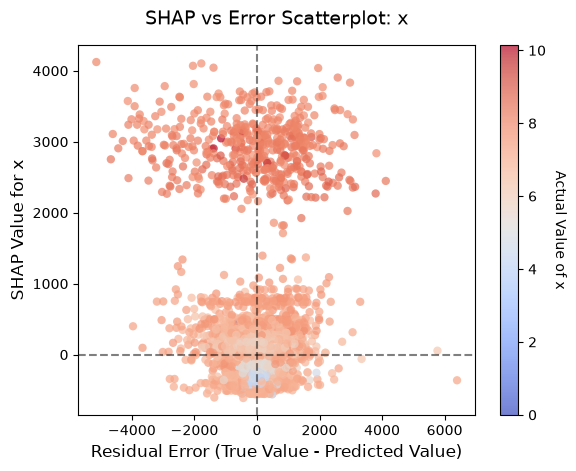

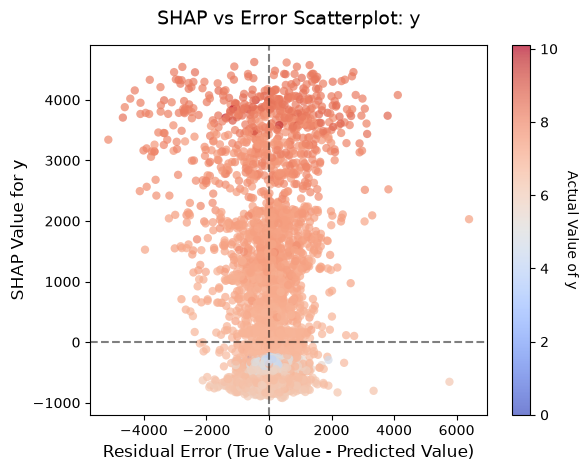

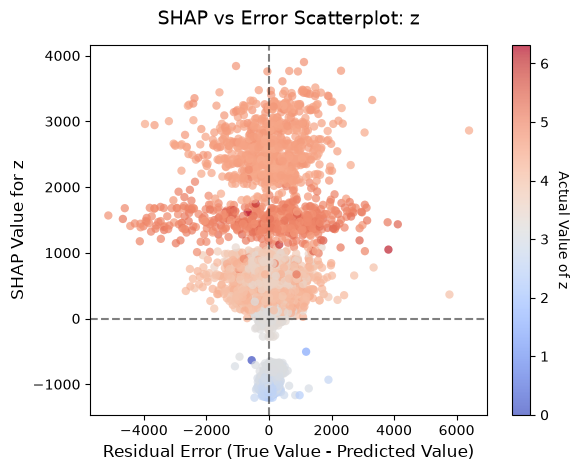

In [10]:
# Get the prediction error.
residuals = y_test - y_pred

columns = X.columns

for column in columns:

    # INSERT YOUR TARGET FEATURE HERE
    feature_column = column

    # Get the index of that column.
    feature_index = X_test.columns.get_loc(feature_column)

    # Get the shap values
    feat_shap_values = shap_values.values[:, feature_index]

    # Get the raw values
    feat_raw_values = X_test[feature_column].values

    # SHAP vs Error Scatterplot
    sc = plt.scatter(residuals, feat_shap_values, c=feat_raw_values, 
                    cmap='coolwarm', alpha=0.7, edgecolors='none')

    # Create lines
    plt.axhline(0, color='black', linestyle='--', alpha=0.5) 
    plt.axvline(0, color='black', linestyle='--', alpha=0.5) 

    # Labels and Styling
    plt.title(f"SHAP vs Error Scatterplot: {feature_column}", fontsize=14, pad=15)
    plt.xlabel("Residual Error (True Value - Predicted Value)", fontsize=12)
    plt.ylabel(f"SHAP Value for {feature_column}", fontsize=12)
    cbar = plt.colorbar(sc)
    cbar.set_label(f"Actual Value of {feature_column}", rotation=270, labelpad=15)
    plt.show()

# Viola, now for every feature you have a graphical output for the models behavior
# AND how much the model valued that particular row.

# This is stupendously powerful visual for figuring out what range of values
# in a feature are difficult for a model to understand. 

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">
<h3> Observations </h3>

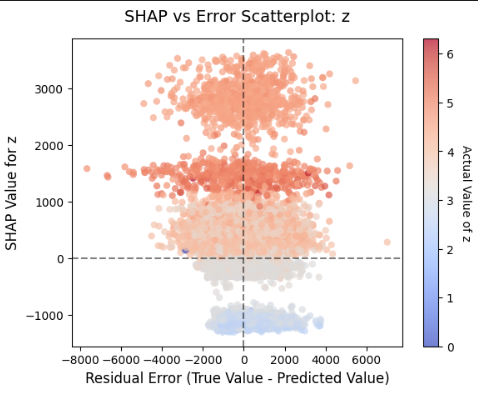

<i>  low values appear to be easier to predict in the `z` column.

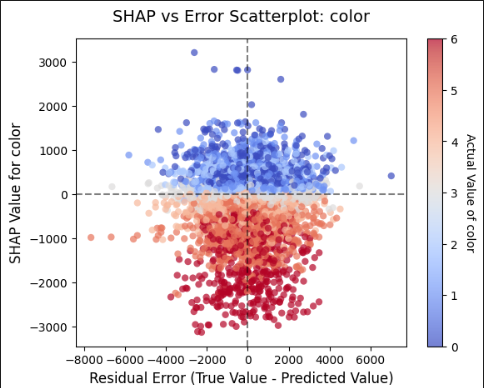

And the reverse seems to be the case here! We can see the linearity between the shap values and the actual value (color). That appears to be the case case for many of the features.



</div>



### <i> Isolating cases with SHAP

Below you'll find a very simple way to isolate cases with `SHAP` so you can inspect them more carefully.

In [11]:
# Create a copy of the test dataframe
predictions_df = X_test.copy()

# Add actual and predicted values
predictions_df["Actual"] = y_test
predictions_df["Predicted"] = y_pred

# Add residuals
predictions_df["Residual"] = residuals

# Sort by the worst predictions
worst_predictions = predictions_df.sort_values("Residual", ascending=False)
worst_predictions

,carat,cut,color,clarity,depth,table,x,y,z,Actual,Predicted,Residual
27673,1.50,2,3,4,60.7,59.0,7.31,7.38,4.46,18691,12293.297145,6397.702855
21935,1.01,0,0,6,64.6,58.0,6.25,6.20,4.02,10011,4239.843212,5771.156788
27161,2.50,0,2,6,65.8,58.0,8.38,8.31,5.49,17405,13285.328010,4119.671990
26194,2.01,0,3,6,65.6,56.0,7.89,7.84,6.16,15562,11742.110641,3819.889359
27726,2.36,3,4,6,59.4,58.0,8.69,8.75,5.18,18745,14950.311187,3794.688813
...,...,...,...,...,...,...,...,...,...,...,...,...
24492,2.05,3,5,3,60.3,59.0,8.25,8.21,4.96,12766,17056.064030,-4290.064030
23292,2.00,0,5,3,58.5,68.0,8.26,8.15,4.80,11322,15755.759321,-4433.759321
23587,2.01,4,3,6,61.5,55.0,8.15,8.11,5.00,11602,16211.278621,-4609.278621
22872,2.32,3,5,6,62.1,58.0,8.47,8.43,5.25,10913,15584.080264,-4671.080264


<i> Use this to translate the worst_predictions index to the shapley_values index: 

In [12]:
# Find the index position in X_test from worst_predictions 
row_position = X_test.index.get_loc(26407)
print(f"The shap_value index is: {row_position}")

The shap_value index is: 7037


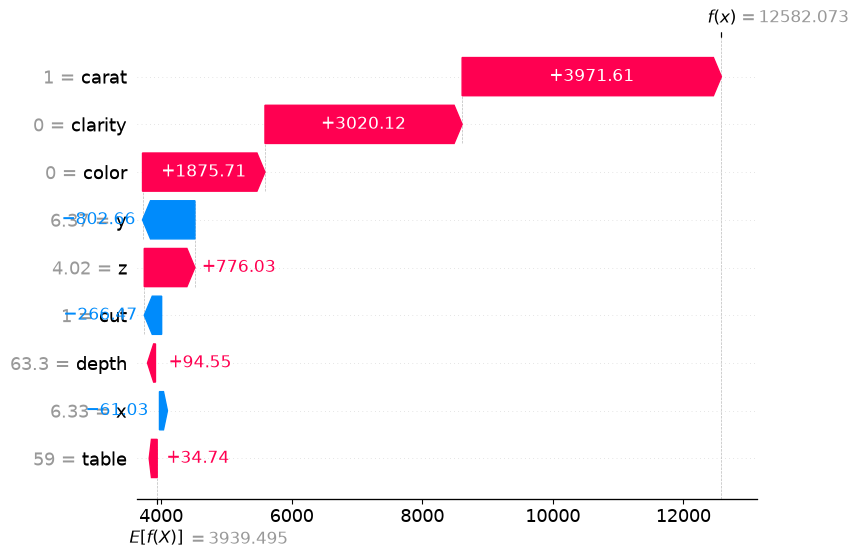

In [13]:
# Feel free to experiment!
shap.plots.waterfall(shap_values[7037])

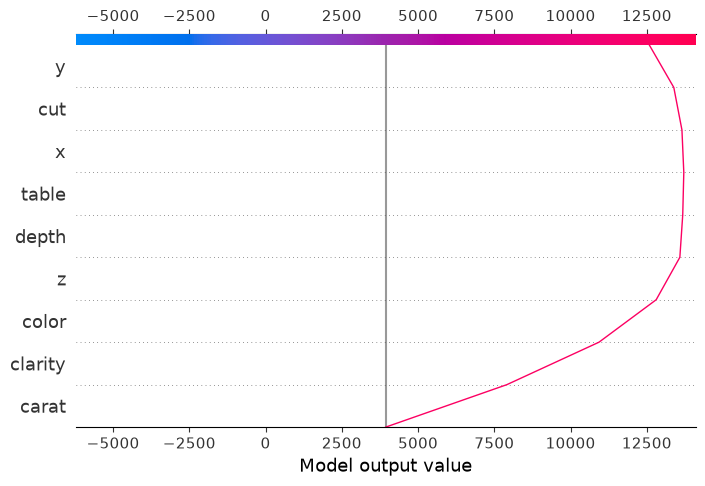

In [14]:
# Decision plot
shap.decision_plot(
    shap_values.base_values[7037],
    shap_values.values[7037],
    feature_names=X_test.columns.tolist(),
    feature_order="hclust",
    show=True
)

---

## <i> Minor Optimizations


In [15]:
df.head(3)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4,1,6,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3,1,5,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1,1,3,56.9,65.0,327,4.05,4.07,2.31


### <i> LOF

In [16]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(
    n_neighbors=30,
    contamination=0.03
)

outlier_predictions = lof.fit_predict(X_train)

inlier_mask = outlier_predictions == 1

X_train_lof = X_train.loc[inlier_mask].copy()
y_train_lof = y_train.loc[inlier_mask].copy()

df = X_train_lof.copy()
df["price"] = y_train_lof

print("Original:", X_train.shape)
print("LOF cleaned:", X_train_lof.shape)
print("Removed:", (~inlier_mask).sum())

Original: (43152, 9)
LOF cleaned: (41857, 9)
Removed: 1295


### <i> Re-training

In [17]:
# X, y -- Test, train split
X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = CatBoostRegressor(
    iterations=100,
    loss_function="RMSE",
    verbose=0,
    random_seed=33891
)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)
print("Model trained and y_pred predicted")

# Metrics recording
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
r_sq = metrics.r2_score(y_test, y_pred)
print("Metrics generated")

# Printing metrics
print("--------------------------")
print("METRICS")
print("--------------------------")
print("MAE")
print(f"{round(mae,2)} \n")
print("MSE")
print(f"{round(mse,2)} \n")
print("RMSE")
print(f"{round(rmse,2)} \n")
print('R-squared:')
print(f"{round(r_sq,2)} \n")

Model trained and y_pred predicted
Metrics generated
--------------------------
METRICS
--------------------------
MAE
298.37 

MSE
305494.86 

RMSE
552.72 

R-squared:
0.98 



### <i> Importance Analysis


In [18]:
# We regenerate SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
print("Shap values created")

Shap values created


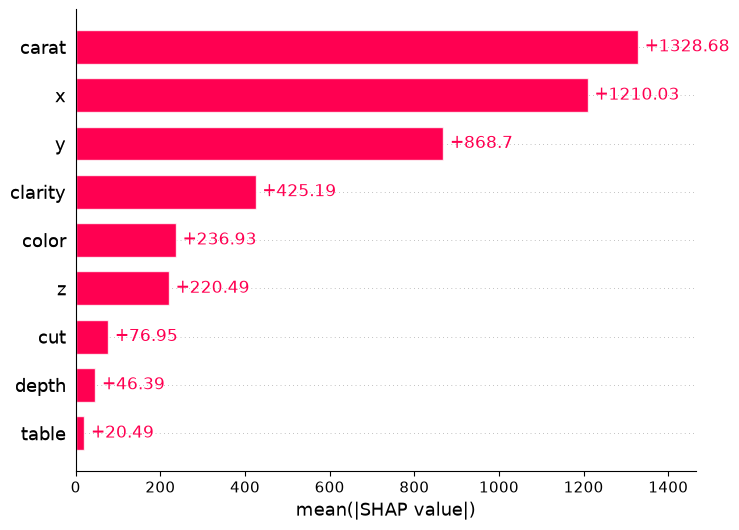

In [19]:
shap.plots.bar(shap_values)

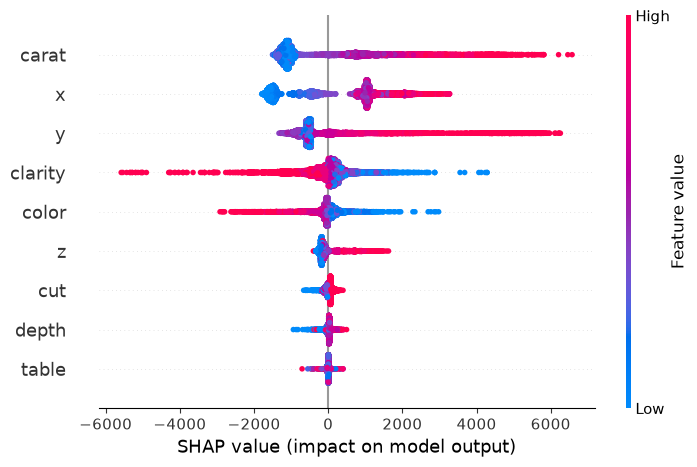

In [20]:
shap.plots.beeswarm(shap_values)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

Eerily similar to the unoptimized dataset. This suggests we have a long way to go.

`x` now has more pronounced importance clusters on the left side. That likely is a good thing, but worth checking.

</div>

### <i> Scatter Plots

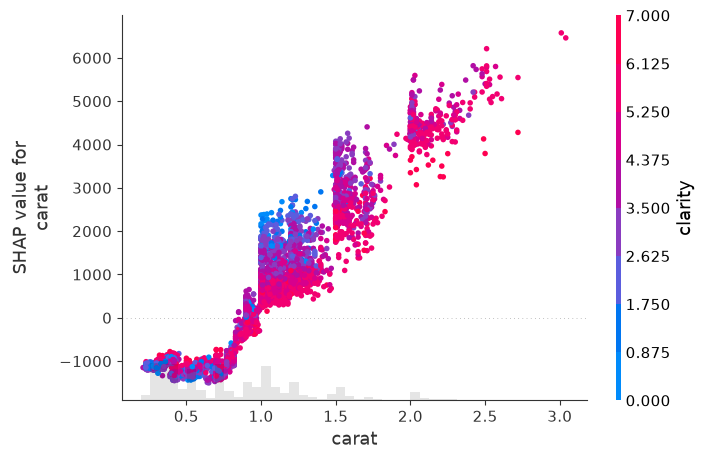

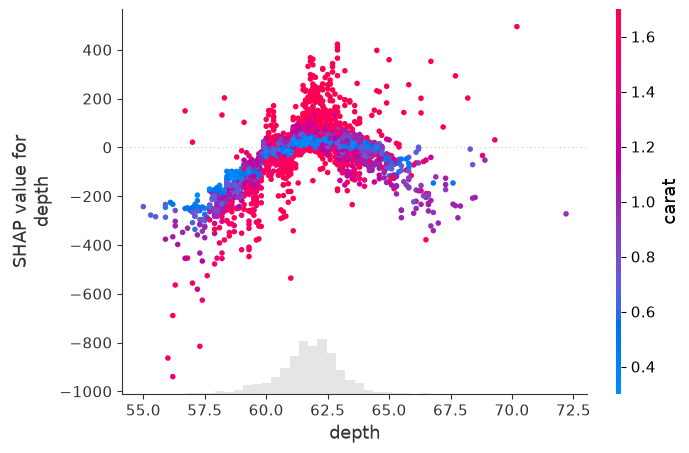

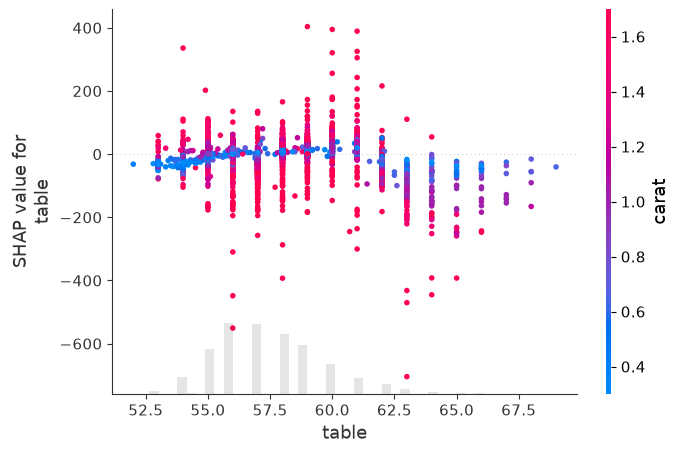

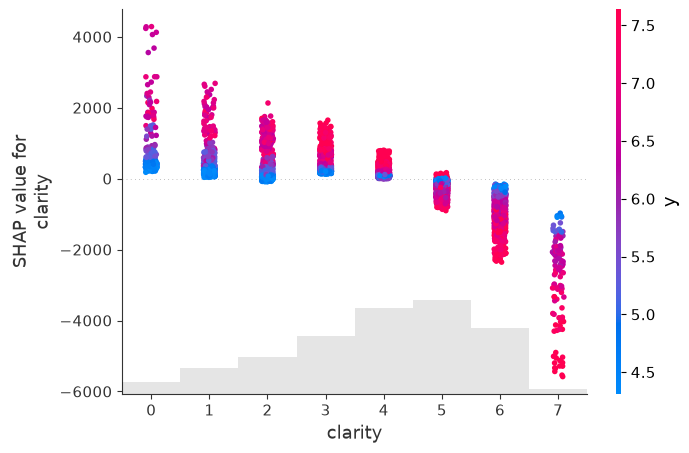

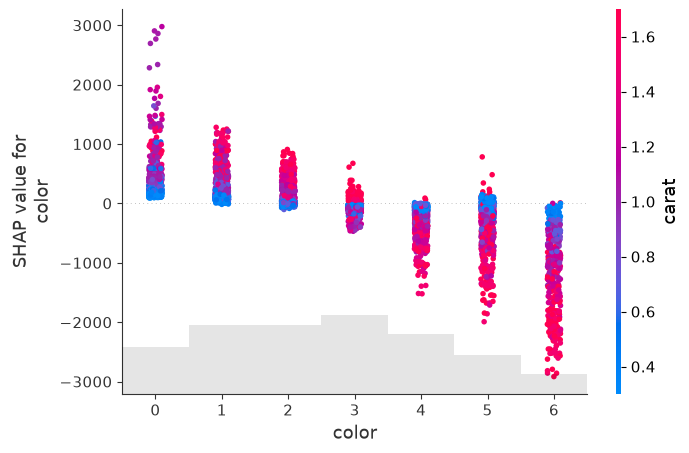

In [21]:
features = ["carat", "depth", "table", "clarity", "color"]

for feature in features:

    shap.plots.scatter(
        shap_values[:, feature],
        color=shap_values,
        show=True
    )

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

|before|after|
|---|---|
|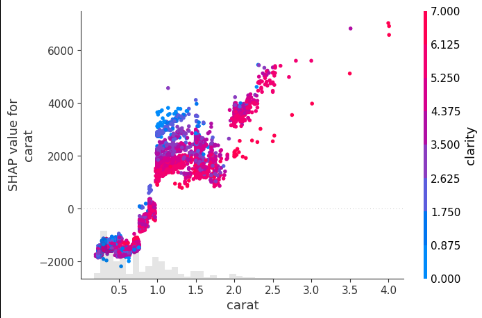|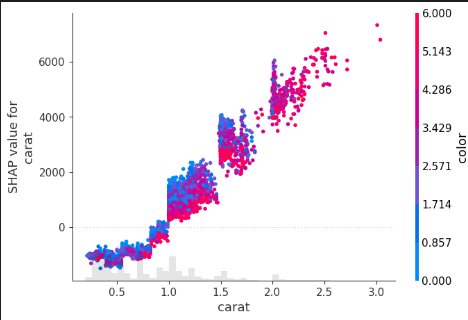|

We are starting to see a much clearer, linear dependency here -- Which suggests that we are unraveling the relationships between features.

|before|after|
|---|---|
|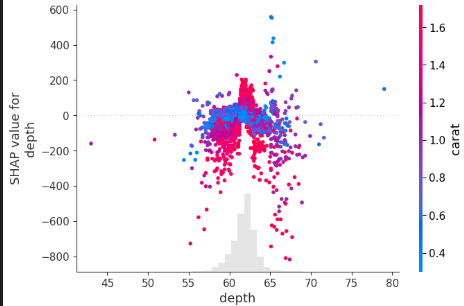|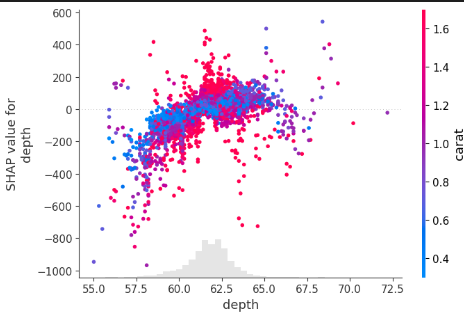|

Even `depth` is a bit more linear. 


We might not have gotten so much better metrics, but we have a much healthier, linear feature vs feature output.

</div>

### <i> Error vs Scatter plot

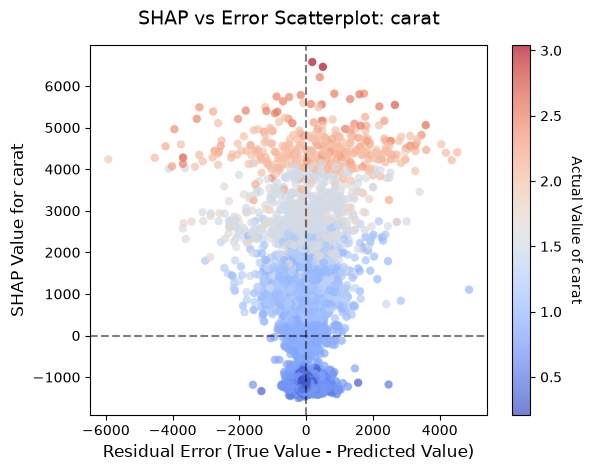

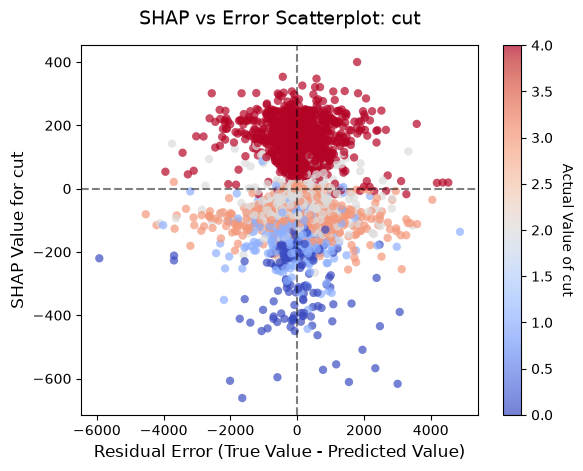

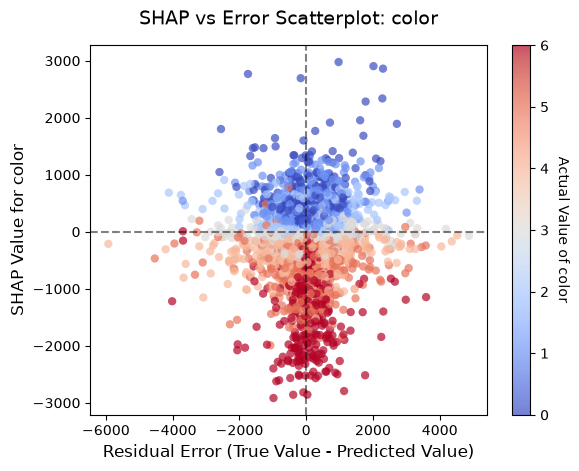

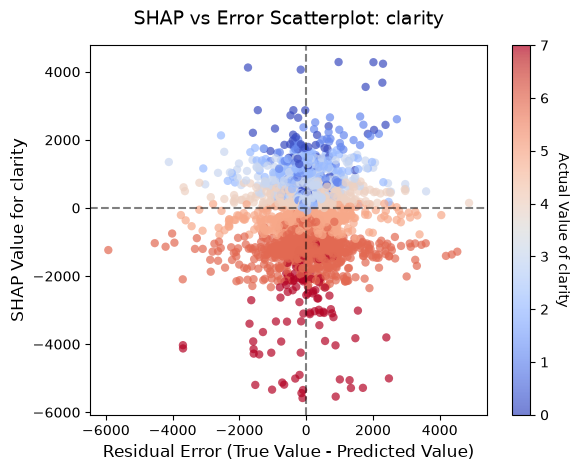

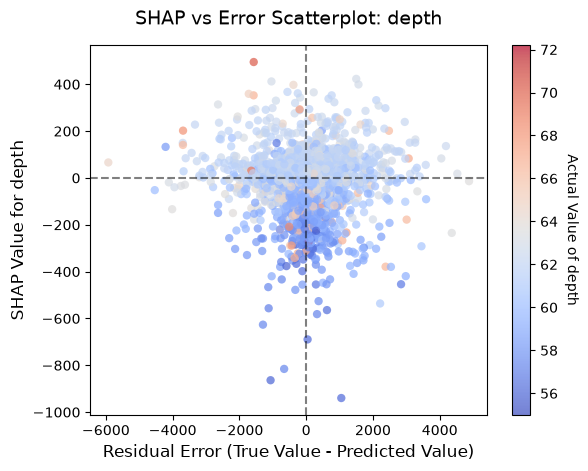

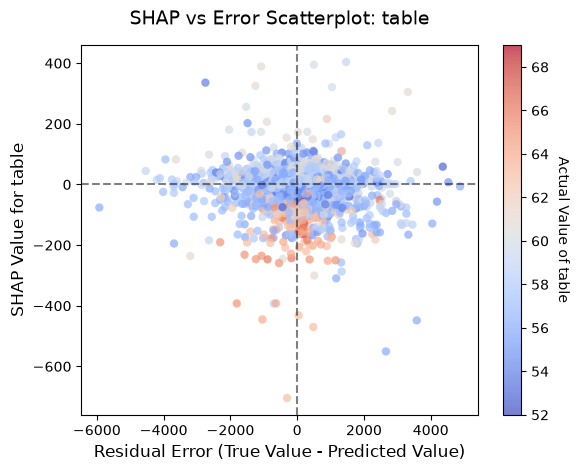

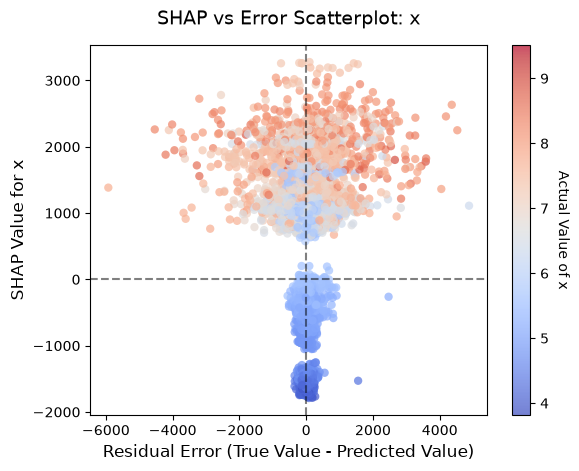

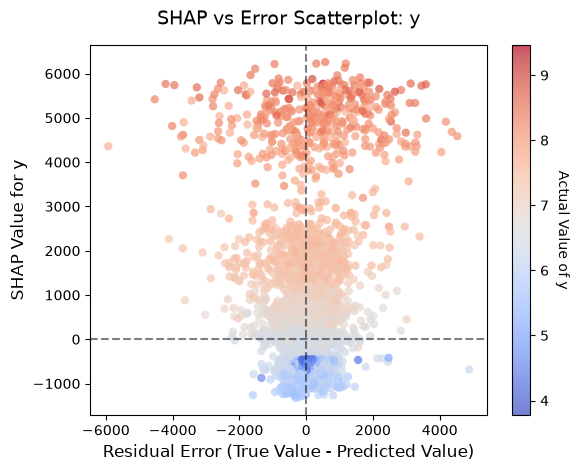

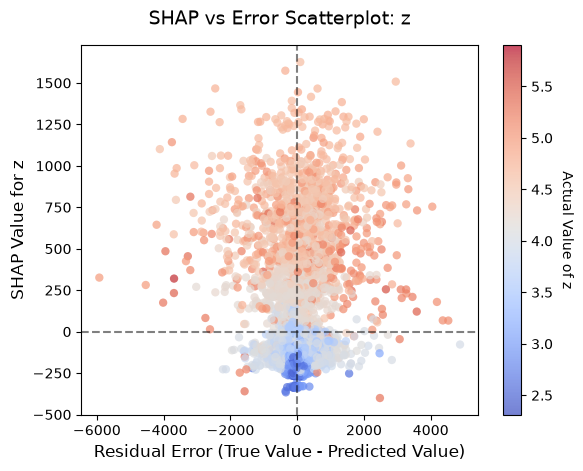

In [22]:
# Get the prediction error.
residuals = y_test - y_pred

columns = X.columns

for column in columns:

    # INSERT YOUR TARGET FEATURE HERE
    feature_column = column

    # Get the index of that column.
    feature_index = X_test.columns.get_loc(feature_column)

    # Get the shap values
    feat_shap_values = shap_values.values[:, feature_index]

    # Get the raw values
    feat_raw_values = X_test[feature_column].values

    # SHAP vs Error Scatterplot
    sc = plt.scatter(residuals, feat_shap_values, c=feat_raw_values, 
                    cmap='coolwarm', alpha=0.7, edgecolors='none')

    # Create lines
    plt.axhline(0, color='black', linestyle='--', alpha=0.5) 
    plt.axvline(0, color='black', linestyle='--', alpha=0.5) 

    # Labels and Styling
    plt.title(f"SHAP vs Error Scatterplot: {feature_column}", fontsize=14, pad=15)
    plt.xlabel("Residual Error (True Value - Predicted Value)", fontsize=12)
    plt.ylabel(f"SHAP Value for {feature_column}", fontsize=12)
    cbar = plt.colorbar(sc)
    cbar.set_label(f"Actual Value of {feature_column}", rotation=270, labelpad=15)
    plt.show()

# Viola, now for every feature you have a graphical output for the models behavior
# AND how much the model valued that particular row.

# This is stupendously powerful visual for figuring out what range of values
# in a feature are difficult for a model to understand. 

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

Because the outliers have been mostly cleared up due to `LOF`, we can see more gradient colors in the scatter vs error plots.

The `x` `y` and `z` values appear to still have less residual errors when the actual values are lower. We could consider looking deeper into those higher actual values. Are bigger diamonds actually harder to predict?

</div>

In [23]:
# Create a copy of the test dataframe
predictions_df = X_test.copy()

# Add actual and predicted values
predictions_df["Actual"] = y_test
predictions_df["Predicted"] = y_pred

# Add residuals
predictions_df["Residual"] = residuals

# Sort by the worst predictions
worst_predictions = predictions_df.sort_values("Residual", ascending=False)
worst_predictions

,carat,cut,color,clarity,depth,table,x,y,z,Actual,Predicted,Residual
22142,1.01,1,3,4,63.6,56.0,6.31,6.24,3.99,10181,5303.369100,4877.630900
27601,2.10,4,4,6,63.1,55.0,8.17,8.13,5.14,18462,13935.923160,4526.076840
27500,2.07,4,4,6,63.5,53.0,8.12,8.09,5.14,18198,13838.034383,4359.965617
27746,2.07,4,3,6,62.5,55.0,8.20,8.13,5.11,18804,14618.266051,4185.733949
27564,2.00,3,4,5,63.0,56.0,7.98,7.93,5.01,18371,14324.698802,4046.301198
...,...,...,...,...,...,...,...,...,...,...,...,...
20838,2.28,1,6,6,63.6,57.0,8.37,8.32,5.31,9068,13082.165424,-4014.165424
23333,1.53,2,2,3,63.2,58.0,7.33,7.30,4.62,11379,15492.384154,-4113.384154
23121,2.20,3,4,6,58.2,59.0,8.52,8.47,4.94,11147,15357.398785,-4210.398785
21971,2.09,3,5,6,60.1,59.0,8.34,8.30,5.00,10042,14577.084938,-4535.084938


In [24]:
# Find the index position in X_test from worst_predictions 
row_position = X_test.index.get_loc(27460)
print(f"The shap_value index is: {row_position}")

The shap_value index is: 8357


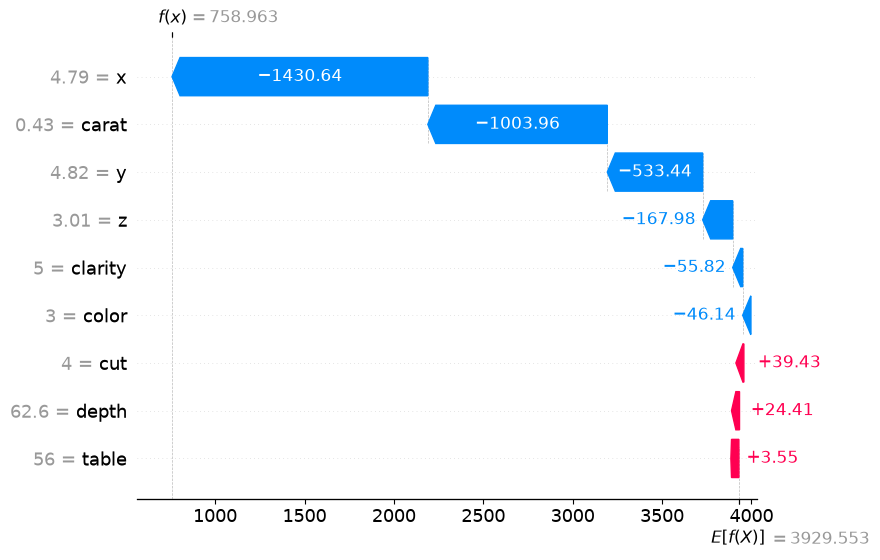

In [25]:
# Feel free to experiment!
shap.plots.waterfall(shap_values[7037])

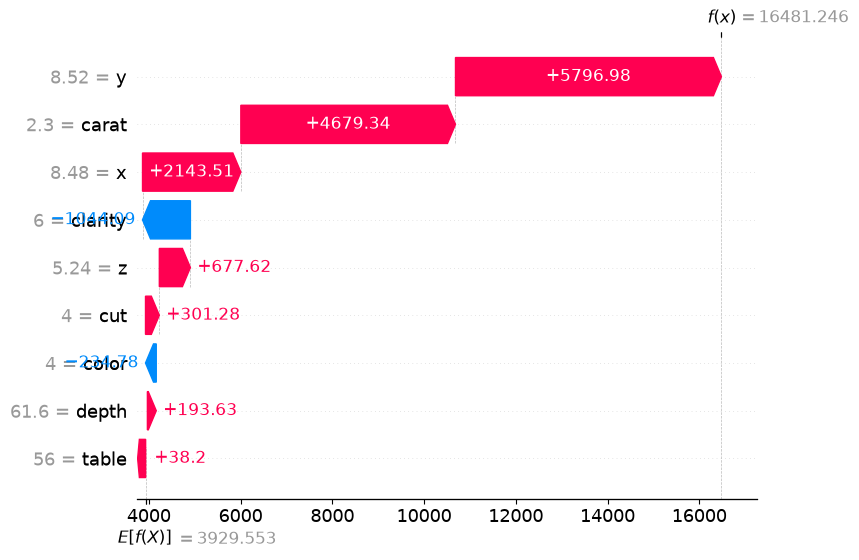

In [26]:
# Feel free to experiment!
shap.plots.waterfall(shap_values[5924])

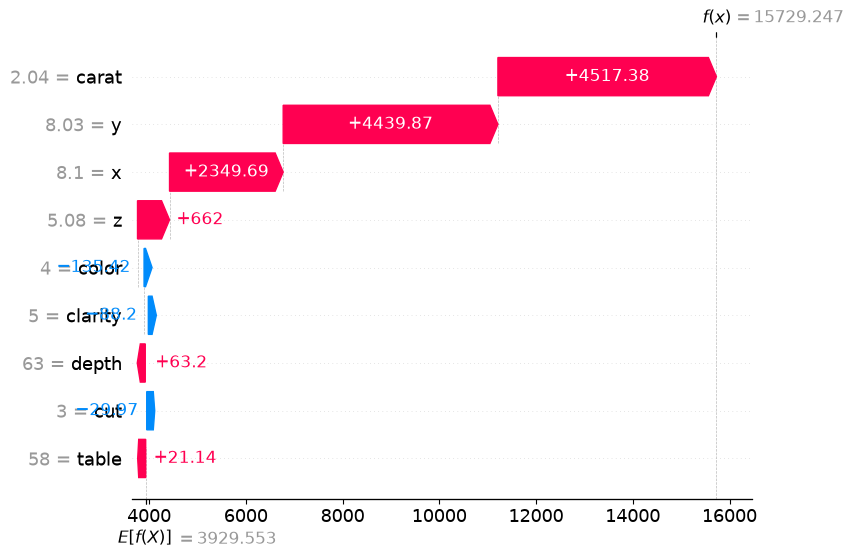

In [27]:
# Feel free to experiment!
shap.plots.waterfall(shap_values[8357])

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

Looks like the dimension features contribute on average the most to the biggest errors. This might suggest that we could use an interaction feature for these features.

perhaps a feature like `df["volume"]` might be beneficial.

</div>